Convert nielson_conversion.json to nielson_data.csv

In [7]:
# Make the Nielson JSON easy to read as a spreadsheet
from nielson_data import NielsonDataCSVConverter

# Define file paths
json_file = "nielson_ome.json"
csv_file = "nielson_data.csv"

# Create an instance of the converter
converter = NielsonDataCSVConverter(json_file, csv_file)

# Convert the JSON to CSV
converter.convert_to_csv()

JSON data has been successfully converted to nielson_data.csv


Add priority assignments to each opioid in nielson_conversions.json

In [6]:
# Import the class
from nielson_data import NielsonDataPriorityUpdater

# Define the JSON file path
json_file = "nielson_ome.json"

# Create an instance of the updater
updater = NielsonDataPriorityUpdater(json_file)

# Define the priority dictionary
priority_dict = {
    1: ['oral_hydromorphone', 'oral_morphine', 'oral_oxycodone','iv_hydromorphone','iv_morphine'],
    2: ['oral_codeine', 'oral_hydrocodone', 'oral_methadone', 'oral_oxymorphone',
        'oral_tapentadol','oral_tramadol','sublingual_buprenorphine','transdermal_fentanyl',
        'iv_fentanyl','sc_fentanyl']
}

# Update the priorities in the JSON file
updater.update_priorities(priority_dict)

Updated JSON data has been saved to nielson_ome.json


Calculate the equivalent opioids from nielson_ome.json

In [2]:
# Conversion Service
from opioid import Opioid
from conversion_service import ConversionService
from nielson_data import NIELSON_CONVERSIONS

conversion_service = ConversionService(NIELSON_CONVERSIONS)

iv_fentanyl = Opioid(administration_method="iv", substance="fentanyl")
oral_hydromorphone = Opioid(administration_method="oral", substance="hydromorphone")
oral_morphine = Opioid(administration_method="oral", substance="morphine")

random_dose = conversion_service.generate_random_dose(iv_fentanyl)
print(f"Random dose for {iv_fentanyl.administration_method}_{iv_fentanyl.substance}: {random_dose:.2f} {iv_fentanyl.unit}")

equivalent_dose_oral_morphine = conversion_service.calculate_expected_dose(random_dose, iv_fentanyl, oral_morphine)
print(f"Equivalent dose for {oral_morphine.administration_method}_{oral_morphine.substance}: {equivalent_dose_oral_morphine:.2f} {oral_morphine.unit}")

Random dose for iv_fentanyl: 56.23 mcg/day
Equivalent dose for oral_morphine: 11.25 mg/day


Construct a prompt

In [4]:
# Prompt Service
from prompt_service import PromptService, PromptedOpioidConversion
from conversion_service import ConversionService
from nielson_data import NIELSON_CONVERSIONS
from opioid import Opioid

# Initialize the PromptService
prompt_service = PromptService(ConversionService(NIELSON_CONVERSIONS))

# Define opioids
iv_fentanyl = Opioid(administration_method="iv", substance="fentanyl", unit="mcg/hour")
oral_hydromorphone = Opioid(administration_method="oral", substance="hydromorphone", unit="mg/day")

# Create a PromptedOpioidConversion object without specifying `from_dose` or `conversion_service`
prompted_conversion = PromptedOpioidConversion(
    from_opioid=iv_fentanyl,
    model="google/gemini-2.5-pro")

# Generate the prompt using the PromptService instance
generated_prompt = prompted_conversion.generate_prompt(prompt_service)

# Print the generated prompt
print("Generated Prompt:")
print(generated_prompt)

# Print the randomly generated `from_dose` and calculated `expected_to_dose`
print(f"\nRandomly Generated Dose: {prompted_conversion.from_dose:.2f} {iv_fentanyl.unit}")
print(f"Expected Dose: {prompted_conversion.expected_to_dose:.2f} {oral_hydromorphone.unit}")

Generated Prompt:
Convert 85.09 mcg/day of fentanyl (iv) to mg/day of morphine (oral).
How many mg/day of morphine (oral) is equivalent to 85.09 mcg/day of fentanyl (iv)?


Express the response in the format {'calculated dose': value}.  Do not include any additional text in your response, only the dictionary.

Randomly Generated Dose: 85.09 mcg/day
Expected Dose: 17.02 mg/day


In [1]:
from prompt_service import PromptService
from conversion_service import ConversionService
from nielson_data import NIELSON_CONVERSIONS
from scenario_vignettes import SCENARIO_VIGNETTES
from scenario import Scenario, ScenarioPromptedConversion

# Initialize the PromptService
prompt_service = PromptService(ConversionService(NIELSON_CONVERSIONS))

# Select a scenario by ID (e.g., "v2")
scenario_dict = SCENARIO_VIGNETTES["v3"]
scenario = Scenario(scenario_dict)

# Create a ScenarioPromptedConversion object
scenario_conversion = ScenarioPromptedConversion(
    scenario,
    model="google/gemini-2.5-pro",
    include_nielson=True
)

# Generate the prompt using the PromptService instance
generated_prompt = scenario_conversion.generate_prompt(prompt_service)

# Print the generated prompt
print("Generated Prompt:")
print(generated_prompt)

# Print the sampled dose and calculated expected_to_dose
print(f"\nScenario Dose: {scenario_conversion.from_dose} {scenario_conversion.from_opioid.unit}")
print(f"Expected Dose: {scenario_conversion.expected_to_dose:.2f} {scenario_conversion.to_opioid.unit}")

Generated Prompt:
A 9 year old child with 30% body surface area burns has been receiving hydromorphone via a PCA pump. The patient used 2.0 mg of intravenous hydromorphone over the past 4 hours. The primary burn service would like to switch the patient to oral morphine. Convert the hydromorphone usage into oral morphine in mg/4hr.

Use the following conversion factor(s):
17.5 OME: 1 mg/day of hydromorphone (iv) is equivalent to 17.5 mg/day morphine (oral).

Express the response in the format {'calculated dose': value}.  Do not include any additional text in your response, only the dictionary.

Scenario Dose: 12 mg/day
Expected Dose: 210.00 mg/day


Ask the model for the equivalent opioid dose

In [5]:
# Run a single conversion with an instance of PromptedOpioidConversion
from conversion_service import ConversionService
from prompt_service import PromptService, PromptedOpioidConversion
from nielson_data import NIELSON_CONVERSIONS
from opioid import Opioid

# Initialize the OpenAI client once
PromptedOpioidConversion.initialize_client()

# Define opioids
iv_fentanyl = Opioid(administration_method="iv", substance="fentanyl", unit="mcg/hour")
oral_hydromorphone = Opioid(administration_method="oral", substance="hydromorphone", unit="mg/day")

# Create a PromptedOpioidConversion object
conversion = PromptedOpioidConversion(
    from_opioid=iv_fentanyl,
    model="google/gemini-2.5-pro",
    include_nielson=True,
    include_examples=True
)

# Generate the prompt
conversion.generate_prompt(prompt_service=PromptService(ConversionService(NIELSON_CONVERSIONS)))

# Query the model
observed_dose = conversion.ask_model()

# Print the results
print("Generated Prompt:")
print(conversion.prompt)
print(f"Observed Dose: {observed_dose:.2f} {oral_hydromorphone.unit}")
print(f"Expected Dose: {conversion.expected_to_dose:.2f} {oral_hydromorphone.unit}")
print(f"Ratio Observed/Expected: {conversion.ratio_observed_expected:.2f}")

Generated Prompt:
Convert 70.64 mcg/day of fentanyl (iv) to mg/day of morphine (oral).
How many mg/day of morphine (oral) is equivalent to 70.64 mcg/day of fentanyl (iv)?

Use the following conversion factor(s):
0.2 OME: 1 mcg/day of fentanyl (iv) is equivalent to 0.2 mg/day morphine (oral).
0.2 OME for fentanyl (iv) means 10 mg/day of morphine (oral) is equivalent to 50.00 mcg/day of fentanyl (iv).
And 120 mg/day of morphine (oral) is equivalent to 600.00 mcg/day of fentanyl (iv).

Express the response in the format {'calculated dose': value}.  Do not include any additional text in your response, only the dictionary.
Observed Dose: 14.13 mg/day
Expected Dose: 14.13 mg/day
Ratio Observed/Expected: 1.00


Run an experiment converting opioids across prompting conditions and models

In [ ]:
# Run an experiment converting opioids across prompting conditions and models
from prompt_service import PromptedOpioidConversion
from opioid import OpioidPairGenerator
from experiment import Experiment

# Initialize all clients
PromptedOpioidConversion.initialize_client()

# Generate opioid pairs
opioid_list_ome = OpioidPairGenerator(lambda priority: priority <= 2 if priority else False)\
    .generate_opioid_list_or_pairs(pairs=False, use_permutations=False)

opioid_pairs = OpioidPairGenerator(lambda priority: priority == 1 if priority else False)\
    .generate_opioid_list_or_pairs(pairs=True, use_permutations=True)

# Define prompt conditions
prompt_conditions = [
    {"include_nielson": False, "include_examples": False},
    {"include_nielson": True, "include_examples": False}
]

# OpenRouter models
models = [
    "openai/gpt-4.1",
    "anthropic/claude-3.5-sonnet:20241022",
    "mistralai/mistral-large-2407",
    "mistralai/mixtral-8x22b-instruct",
    "google/gemini-2.5-pro",
    "cohere/command-r-plus-08-2024",
    "ai21/jamba-large-1.7",
    "ai21/jamba-mini-1.7",
    "qwen/qwen-2.5-72b-instruct",
    "meta-llama/llama-3.3-70b-instruct",
    "deepseek/deepseek-chat"
]

# Run OME experiment
experiment_ome = Experiment(opioid_list_ome, prompt_conditions, models, repetitions=18)
experiment_ome.run()

# Print the OME experiment ID
print(f"Experiment ID: {experiment_ome.experiment_id}")

# Run pairs experiment
experiment_pairs = Experiment(opioid_pairs, prompt_conditions, models, repetitions=18)
experiment_pairs.run()

# Print the pairs experiment ID
print(f"Experiment ID: {experiment_pairs.experiment_id}")

In [2]:
# Run missing experiments for pairs without Nielson
from prompt_service import PromptedOpioidConversion
from opioid import OpioidPairGenerator
from experiment import Experiment

# Initialize client
PromptedOpioidConversion.initialize_client()

# Generate only direct pairs (not OME)
opioid_pairs = OpioidPairGenerator(lambda priority: priority == 3 if priority else False)\
    .generate_opioid_list_or_pairs(pairs=False, use_permutations=False)

# Only models with missing data
models = [
        "openai/gpt-4.1",
        "openai/gpt-4.1-mini",
        "openai/gpt-3.5-turbo",
        "anthropic/claude-3.5-sonnet:20241022",
        "anthropic/claude-3-5-haiku-20241022",
        "mistralai/mistral-large-2407",
        "mistralai/mixtral-8x22b-instruct",
        "google/gemini-2.5-pro",
        "google/gemini-2.5-flash",
        "cohere/command-r-plus-08-2024",
        "ai21/jamba-large-1.7",
        "ai21/jamba-mini-1.7",
        "qwen/qwen-2.5-72b-instruct",
        "meta-llama/llama-3.3-70b-instruct",
        "deepseek/deepseek-chat"
    ]

# Only the condition without Nielson
prompt_conditions = [
    {"include_nielson": False, "include_examples": False},
    {"include_nielson": True, "include_examples": False}
]

# Run experiment for missing data
experiment = Experiment(opioid_pairs, prompt_conditions, models, repetitions=18)
experiment.run()

print(f"Experiment ID: {experiment.experiment_id}")

Error during conversion: OpenRouter API error for model anthropic/claude-3-5-haiku-20241022: Error code: 429 - {'error': {'message': 'Provider returned error', 'code': 429, 'metadata': {'raw': 'anthropic/claude-3.5-haiku-20241022 is temporarily rate-limited upstream. Please retry shortly, or add your own key to accumulate your rate limits: https://openrouter.ai/settings/integrations', 'provider_name': 'Google'}}, 'user_id': 'user_35JqlkFJdJc4aK8FTkdGB2SlQqn'}
Error during conversion: OpenRouter API error for model anthropic/claude-3-5-haiku-20241022: Error code: 429 - {'error': {'message': 'Provider returned error', 'code': 429, 'metadata': {'raw': 'anthropic/claude-3.5-haiku-20241022 is temporarily rate-limited upstream. Please retry shortly, or add your own key to accumulate your rate limits: https://openrouter.ai/settings/integrations', 'provider_name': 'Google'}}, 'user_id': 'user_35JqlkFJdJc4aK8FTkdGB2SlQqn'}
Error during conversion: OpenRouter API error for model anthropic/claude

Organize all results by whether they include oral morphine

In [3]:
from experiment_utils import add_ome_column

add_ome_column(
    input_csv="experiment_results.csv",
    output_csv="experiment_results_by_ome.csv"
)

Added 'ome' column to experiment_results_by_ome.csv


Organize results by opioid pairs, find consensus across prompt conditions

In [4]:
from opioid_pair_model_result import OpioidPairModelResult
from opioid_pair_consensus import OpioidPairConsensus
from conversion_service import ConversionService
from nielson_data import NIELSON_CONVERSIONS
from prefix import harmonize_model_names

harmonize_model_names("experiment_results_by_ome.csv")

# Initialize conversion service
conversion_service = ConversionService(NIELSON_CONVERSIONS)

# Process all combinations in the experiment_results_by_ome.csv
results = OpioidPairModelResult.process_all_combinations(
    csv_file="experiment_results_by_ome.csv",
    output_file="pair_model_analysis.csv",
    conversion_service=conversion_service,
    verbose=True
)

# Process all combinations in the pair_model_analysis.csv
results = OpioidPairConsensus.process_all_combinations(
    csv_file="pair_model_analysis.csv",
    output_file="opioid_pair_consensus.csv",
    conversion_service=conversion_service,
    verbose=True
)

# Update pair_model_analysis.csv with consensus results
updated_df = OpioidPairConsensus.update_pair_model_analysis(
    pair_model_csv="pair_model_analysis.csv",
    consensus_csv="opioid_pair_consensus.csv",
    output_csv="pair_model_analysis.csv",
    verbose=True
)

Harmonized model names written to experiment_results_by_ome.csv
Processed 10/1582 combinations...
Processed 20/1582 combinations...
Processed 30/1582 combinations...
Processed 40/1582 combinations...
Processed 50/1582 combinations...
Processed 60/1582 combinations...
Processed 70/1582 combinations...
Processed 80/1582 combinations...
Processed 90/1582 combinations...
Processed 100/1582 combinations...


/Users/tanyamarton/opioid-conversion-experiment/opioid_pair_model_result.py:123: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  slope, intercept, r_value, p_value, std_err = stats.linregress(dose_to, log_coefficients)


Processed 110/1582 combinations...
Processed 120/1582 combinations...
Processed 130/1582 combinations...
Processed 140/1582 combinations...
Processed 150/1582 combinations...
Processed 160/1582 combinations...
Processed 170/1582 combinations...
Processed 180/1582 combinations...
Processed 190/1582 combinations...
Processed 200/1582 combinations...
Processed 210/1582 combinations...
Processed 220/1582 combinations...
Processed 230/1582 combinations...
Processed 240/1582 combinations...
Processed 250/1582 combinations...
Processed 260/1582 combinations...
Processed 270/1582 combinations...
Processed 280/1582 combinations...
Processed 290/1582 combinations...
Processed 300/1582 combinations...
Processed 310/1582 combinations...
Processed 320/1582 combinations...
Processed 330/1582 combinations...
Processed 340/1582 combinations...
Processed 350/1582 combinations...
Processed 360/1582 combinations...
Processed 370/1582 combinations...
Processed 380/1582 combinations...
Processed 390/1582 c

In [5]:
# Make a CSV of model batch means for weight, tight, and broad ranges

from model_means import ModelBatchMeansBuilder

# Update combinations to use 'batch_name' instead of 'name'
combinations = [
    {"ome": None, "include_nielson": False, "batch_name": "all_n0"},
    {"ome": None, "include_nielson": True, "batch_name": "all_n1"},
    {"ome": True, "include_nielson": False, "batch_name": "ome_n0"},
    {"ome": True, "include_nielson": True, "batch_name": "ome_n1"},
    {"ome": False, "include_nielson": False, "batch_name": "pairs_n0"},
    {"ome": False, "include_nielson": True, "batch_name": "pairs_n1"},
]

builder = ModelBatchMeansBuilder("pair_model_analysis.csv")
builder.save_means_df(combinations, "model_batch_means.csv")

✓ Saved batch means to model_batch_means.csv


In [1]:
# Use the current version of the heatmap visualizer to make a bar chart (no updates)

from opioid_pair_batch import OpioidPairBatch
from opioid_pair_batch_heatmap_visualizer import OpioidPairBatchHeatmapVisualizer
from bokeh.plotting import show

# If you want to use the current method, you need to provide a batch object
# Example: create a batch for the desired batch_name
batch_name = "ome_n1"  # Change to your desired batch

# You may need to construct filter_specs to match your batch_name logic
filter_spec = {
    "include_nielson": True,  # Set according to batch_name
    "include_examples": False,
    "exclude_self_pairs": True,
    "ome": True  # Set according to batch_name
}
filter_specs = [filter_spec]

batch = OpioidPairBatch.from_filter_specs(
    experiment_results_csv="experiment_results_by_ome.csv",
    pair_model_csv="pair_model_analysis.csv",
    consensus_csv="opioid_pair_consensus.csv",
    filter_specs=filter_specs,
)

heatmap_vis = OpioidPairBatchHeatmapVisualizer(batch)
bar_chart = heatmap_vis._create_mean_accuracy_bar_chart(width=900, height=400)
show(bar_chart)

Found 16 models and 14 pairs
Weight matrix shape: (17, 15)
Non-NaN values in weight matrix: 252


In [6]:
from opioid_pair_batch import OpioidPairBatch
from opioid_pair_batch_visualizer import OpioidPairBatchVisualizer
from opioid_pair_batch_heatmap_visualizer import OpioidPairBatchHeatmapVisualizer
from visualization_config import convert_to_pdf_auto_size

combinations = [
    {"ome": None, "include_nielson": False, "name": "all_n0"},
    {"ome": None, "include_nielson": True, "name": "all_n1"},    
    {"ome": True, "include_nielson": False, "name": "ome_n0"},
    {"ome": True, "include_nielson": True, "name": "ome_n1"},  
    {"ome": False, "include_nielson": False, "name": "pairs_n0"},
    {"ome": False, "include_nielson": True, "name": "pairs_n1"},  
]

for combo in combinations:
    filter_spec = {
        "include_nielson": combo["include_nielson"],
        "include_examples": False,
        "exclude_self_pairs": True,
    }
    if combo["ome"] is not None:
        filter_spec["ome"] = combo["ome"]
    filter_specs = [filter_spec]
    
    try:
        batch = OpioidPairBatch.from_filter_specs(
            experiment_results_csv="experiment_results_by_ome.csv",
            pair_model_csv="pair_model_analysis.csv",
            consensus_csv="opioid_pair_consensus.csv",
            filter_specs=filter_specs,
        )

        vis = OpioidPairBatchVisualizer(
            batch,
            row_width=600,
            row_height=300,
        )

        batch_html = f"{combo['name']}_batch.html"
        vis.create_grid(output_html=batch_html)
        print(f"✓ Saved Bokeh HTML to {batch_html}")
        
        # Convert Bokeh to PDF
        batch_pdf = f"{combo['name']}_batch.pdf"
        await convert_to_pdf_auto_size(batch_html, batch_pdf, scale=2.0)
        print(f"✓ Saved Bokeh PDF to {batch_pdf}")

        heatmap_vis = OpioidPairBatchHeatmapVisualizer(
            batch,
            cell_size=35,
            width_padding=0,
            height_padding=0,
            cell_text_size="6pt",
            label_text_size="7pt"
        )

        # Save HTML
        output_html = f"{combo['name']}_heatmaps.html"
        heatmap_vis.create_heatmaps(output_html=output_html)
        print(f"✓ Saved HTML to {output_html}")
        
        # Convert to PDF
        output_pdf = f"{combo['name']}_heatmaps.pdf"
        await convert_to_pdf_auto_size(output_html, output_pdf, scale=3.0)
        print(f"✓ Saved PDF to {output_pdf}")

    except Exception as e:
        print(f"✗ Error creating {combo['name']}: {e}")

✓ Saved Bokeh HTML to all_n0_batch.html
✓ Generated PDF: 1445px x 14720px
✓ Saved Bokeh PDF to all_n0_batch.pdf
Found 16 models and 49 pairs
Weight matrix shape: (17, 50)
Non-NaN values in weight matrix: 813
Heatmaps saved to all_n0_heatmaps.html
✓ Saved HTML to all_n0_heatmaps.html
✓ Generated PDF: 1770px x 2055px
✓ Saved PDF to all_n0_heatmaps.pdf
✓ Saved Bokeh HTML to all_n1_batch.html
✓ Generated PDF: 1445px x 14720px
✓ Saved Bokeh PDF to all_n1_batch.pdf
Found 16 models and 49 pairs
Weight matrix shape: (17, 50)
Non-NaN values in weight matrix: 829
Heatmaps saved to all_n1_heatmaps.html
✓ Saved HTML to all_n1_heatmaps.html
✓ Generated PDF: 1770px x 2055px
✓ Saved PDF to all_n1_heatmaps.pdf
✓ Saved Bokeh HTML to ome_n0_batch.html
✓ Generated PDF: 1445px x 5720px
✓ Saved Bokeh PDF to ome_n0_batch.pdf
Found 16 models and 19 pairs
Weight matrix shape: (17, 20)
Non-NaN values in weight matrix: 327
Heatmaps saved to ome_n0_heatmaps.html
✓ Saved HTML to ome_n0_heatmaps.html
✓ Generated P

In [7]:
from opioid_model_comparison_bar_visualizer import ModelComparisonFigureBuilder

builder = ModelComparisonFigureBuilder()
await builder.save("model_comparison_bar.html", "model_comparison_bar.pdf")  # Bokeh bar charts
builder.save_scatter_figures_pdf("model_comparison_scatter.pdf") 

✓ Generated PDF: 1300px x 986px


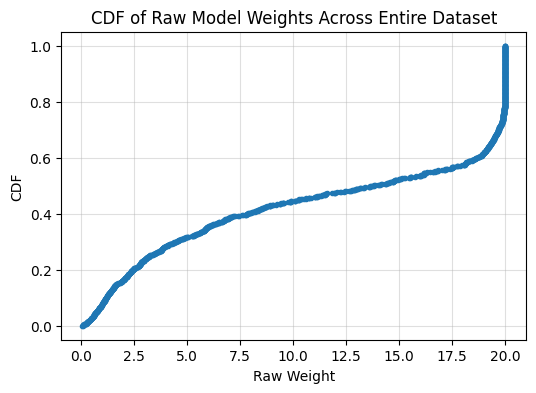

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load your dataset
df = pd.read_csv("pair_model_analysis.csv")

# Extract raw weights
weights = df["weight"].dropna().astype(float)

# Sort for CDF
sorted_w = np.sort(weights)
cdf = np.arange(1, len(sorted_w) + 1) / len(sorted_w)

# Plot
plt.figure(figsize=(6, 4))
plt.plot(sorted_w, cdf, marker='.', linestyle='none')

plt.xlabel("Raw Weight")
plt.ylabel("CDF")
plt.title("CDF of Raw Model Weights Across Entire Dataset")
plt.grid(True, alpha=0.4)

plt.show()


In [ ]:
from opioid_model_comparison_bar_visualizer import OpioidModelComparisonBarVisualizer
from bokeh.layouts import row, column
from bokeh.io import output_file, save

combinations_list = [
    [
        {"ome": True, "include_nielson": False, "name": "ome_n0"},
        {"ome": True, "include_nielson": True, "name": "ome_n1"},
    ],
    [
        {"ome": False, "include_nielson": False, "name": "pairs_n0"},
        {"ome": False, "include_nielson": True, "name": "pairs_n1"},
    ],
    [
        {"ome": None, "include_nielson": False, "name": "all_n0"},
        {"ome": None, "include_nielson": True, "name": "all_n1"},
    ]
]

titles = [
    "OME Comparison",
    "Pairs Comparison",
    "All Comparison"
]

figures = []
for combos, title in zip(combinations_list, titles):
    visualizer = OpioidModelComparisonBarVisualizer.from_combinations(
        combos,
        experiment_results_csv="experiment_results_by_ome.csv",
        pair_model_csv="pair_model_analysis.csv",
        consensus_csv="opioid_pair_consensus.csv"
    )
    fig = visualizer.plot(title=title)
    figures.append(fig)

output_file("model_comparison_bar.html")
save(column(*figures))